# Parte 1 – Reconstrucción de las marcas del ecógrafo

Durante el estudio, el ecografista dibuja **marcas** sobre la imagen: cruces para medir la lesión (*calipers*), líneas punteadas entre ellas, textos con la ubicación (por ejemplo "RT AXILLA") y recuadros. El equipo las "quema" en la imagen al guardarla, así que en BUSI **reemplazan los píxeles de tejido** que había debajo.

**Por qué hay que sacarlas.** No son tejido, pero el análisis las trataría como si lo fueran:
- en la caracterización del ruido (Parte 2) agregan valores que no son speckle;
- en los mapas de textura (Parte 4) aparecen como puntos de contraste muy alto, que la segmentación puede confundir con bordes;
- cuando caen sobre el borde del tumor (pasa seguido, porque justamente miden la lesión), alteran sus descriptores (Parte 6).

Esta limpieza **no reduce el speckle**: saca estructuras que no pertenecen a la imagen ecográfica. Corresponde al paso de **reconstrucción** de la consigna.

**Contenido**
1. Cómo son las marcas
2. ¿Alcanza con buscar el blanco puro?
3. Detección con transformada *top-hat*
4. Reconstrucción con *inpainting*
5. Validación con marcas sintéticas
6. Lo que la validación nos hizo corregir
7. Conclusiones

### Preparación

Igual que en las partes anteriores: le decimos a Python dónde está nuestro código (`src/`) e importamos lo que vamos a usar.

In [13]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [14]:
import numpy as np
import matplotlib.pyplot as plt

from busi.datos import listar_casos, cargar_caso
from busi import artefactos

casos = listar_casos().set_index("id")     # indexamos por nombre para poder pedir un caso: casos.loc["benign (252)"]

## 1. Cómo son las marcas

Elegimos tres imágenes donde las marcas se ven bien: dos con *calipers* y texto, y una con texto solamente.

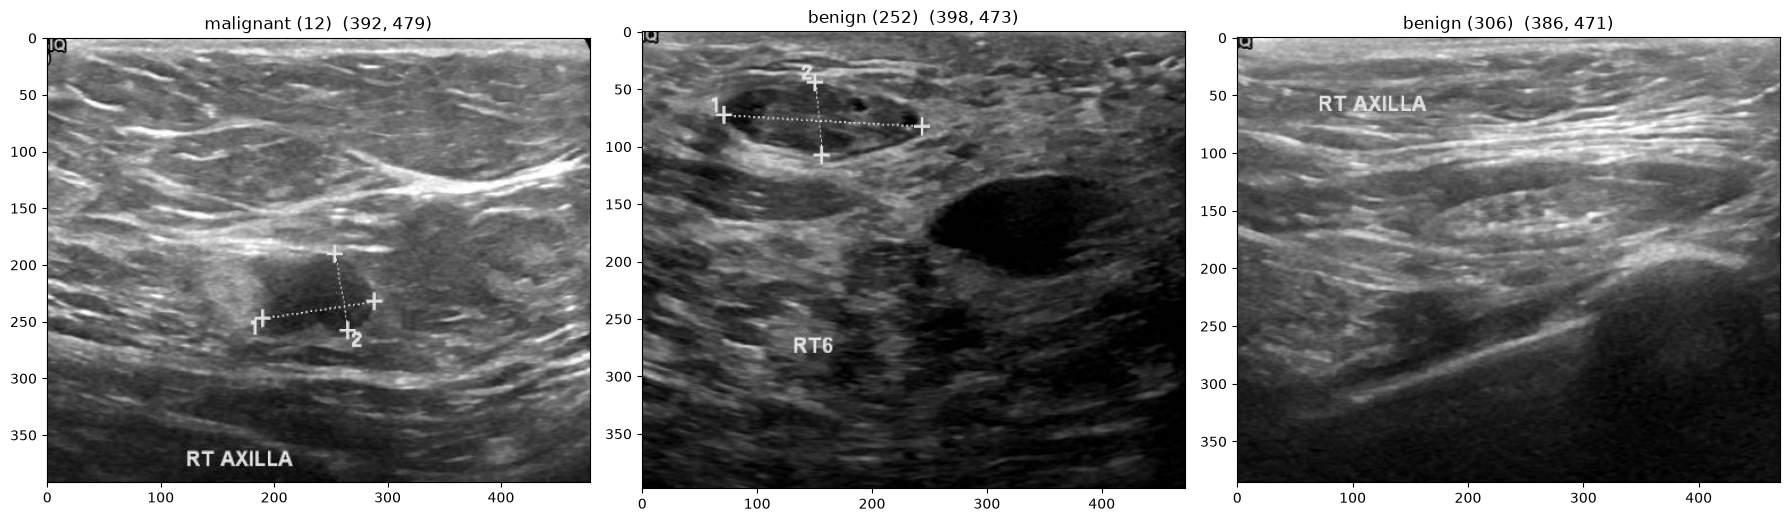

In [15]:
ejemplos = ["malignant (12)", "benign (252)", "benign (306)"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, id_caso in zip(axes, ejemplos):
    img, mascara = cargar_caso(casos.loc[id_caso])
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{id_caso}  {img.shape}")
plt.tight_layout()
plt.show()

Para ver cómo están hechas, hacemos **zoom** sobre las cruces de `malignant (12)`. Con `interpolation="nearest"` cada píxel se dibuja como un cuadradito, sin suavizar, así se ve el tamaño real de las marcas.

Para **medir** su grosor (y no estimarlo a ojo) usamos un **perfil de intensidad**: tomamos los píxeles que están sobre una línea que **cruza** la marca y graficamos el nivel de gris de cada uno. Es como caminar atravesando la cruz y anotar el gris en cada paso: mientras estamos sobre tejido el valor es bajo, al pisar la marca sube, y al salir vuelve a bajar. **El grosor de la marca es la cantidad de píxeles en los que el valor queda alto.**

Medimos dos perfiles:
- **rojo:** una línea horizontal que cruza el brazo **vertical** de la cruz de arriba;
- **celeste:** una línea vertical que cruza el brazo **horizontal** de la cruz de la derecha.

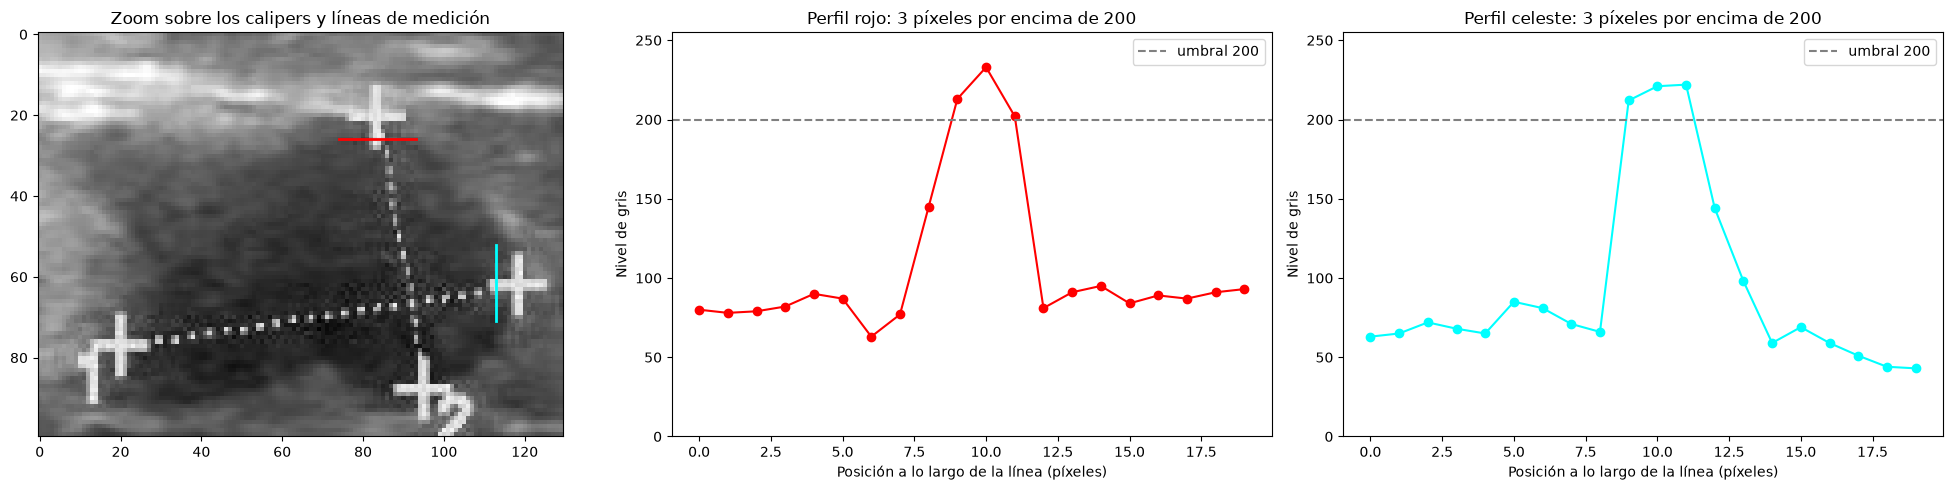

Perfil rojo:    [80, 78, 79, 82, 90, 87, 63, 77, 145, 213, 233, 202, 81, 91, 95, 84, 89, 87, 91, 93]
Perfil celeste: [63, 65, 72, 68, 65, 85, 81, 71, 66, 212, 221, 222, 144, 98, 59, 69, 59, 51, 44, 43]

En todo el recorte: 932 píxeles >= 200, de los cuales solo 13 valen 255


In [16]:
img, mascara = cargar_caso(casos.loc["malignant (12)"])
recorte = img[170:270, 170:300]            # filas 170 a 270, columnas 170 a 300: la zona de las cruces

perfil_rojo = recorte[26, 74:94]           # fila 26, columnas 74 a 93
perfil_celeste = recorte[52:72, 113]       # columna 113, filas 52 a 71
UMBRAL = 200                               # sobre estas dos líneas el tejido no supera ~150; las marcas sí superan 200

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].imshow(recorte, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[0].plot([74, 93], [26, 26], color="red", linewidth=2)
axes[0].plot([113, 113], [52, 71], color="cyan", linewidth=2)
axes[0].set_title("Zoom sobre los calipers y líneas de medición")

for ax, perfil, color, nombre in [(axes[1], perfil_rojo, "red", "rojo"),
                                  (axes[2], perfil_celeste, "cyan", "celeste")]:
    ax.plot(perfil, "o-", color=color)
    ax.axhline(UMBRAL, color="gray", linestyle="--", label=f"umbral {UMBRAL}")
    ax.set_ylim(0, 255)
    ax.set_xlabel("Posición a lo largo de la línea (píxeles)")
    ax.set_ylabel("Nivel de gris")
    ax.set_title(f"Perfil {nombre}: {(perfil >= UMBRAL).sum()} píxeles por encima de {UMBRAL}")
    ax.legend()
plt.tight_layout()
plt.show()

print("Perfil rojo:   ", perfil_rojo.tolist())
print("Perfil celeste:", perfil_celeste.tolist())
print(f"\nEn todo el recorte: {(recorte >= 200).sum()} píxeles >= 200, de los cuales solo {(recorte == 255).sum()} valen 255")

**Qué vemos:**
- En los dos perfiles el tejido está entre ~60 y ~100; al cruzar la marca el valor **salta a 210–233 durante exactamente 3 píxeles** y vuelve a bajar. Las marcas son estructuras **muy finas: 3 píxeles de grosor**. A los costados hay un píxel de transición (145 en el perfil rojo, 144 en el celeste), porque el equipo suaviza el borde del dibujo.
- **Los valores de la marca no son 255**: el máximo es 233. En todo el recorte hay 932 píxeles por encima de 200 y solo 13 valen 255.
- Además de las cruces aparecen **números** ("1", "2") que identifican cada medición, del mismo grosor y brillo.

Las marcas se reconocen entonces por dos cosas: son **finas** (3 px) y tienen **mucho contraste con su vecindad inmediata** (saltan más de 100 niveles de gris respecto del tejido de al lado). Esas dos propiedades son las que vamos a usar para detectarlas.

## 2. ¿Alcanza con buscar el blanco puro?

En la Parte 0 vimos que 620 de las 780 imágenes llegan al valor 255 y supusimos que el blanco puro "muchas veces" eran marcas. Lo verificamos: pintamos de **rojo** los píxeles con valor ≥ 250 en cuatro imágenes.

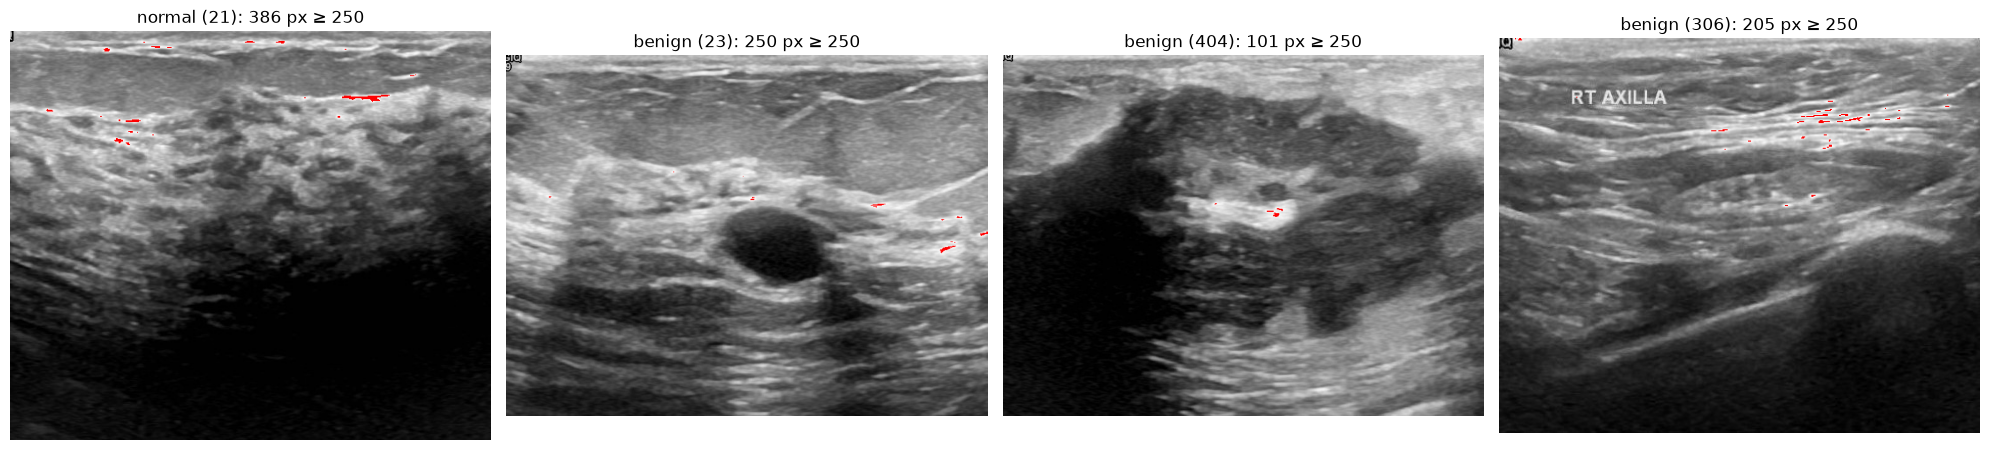

In [17]:
def pintar(img, seleccion, color=(255, 0, 0)):
    """Imagen en RGB con los píxeles de `seleccion` pintados de `color`."""
    rgb = np.dstack([img, img, img])      # gris -> 3 canales iguales
    rgb[seleccion] = color
    return rgb

ejemplos_sat = ["normal (21)", "benign (23)", "benign (404)", "benign (306)"]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, id_caso in zip(axes, ejemplos_sat):
    img, mascara = cargar_caso(casos.loc[id_caso])
    saturados = img >= 250
    ax.imshow(pintar(img, saturados))
    ax.set_title(f"{id_caso}: {saturados.sum()} px ≥ 250")
    ax.axis("off")
plt.tight_layout()
plt.show()

Y contamos en todo el dataset cuántos píxeles saturados tiene cada imagen:

In [18]:
n_saturados = []
for id_caso, caso in casos.iterrows():
    img, mascara = cargar_caso(caso)
    n_saturados.append((img >= 250).sum())
n_saturados = np.array(n_saturados)

print(f"Imágenes sin ningún píxel >= 250:     {(n_saturados == 0).sum()} de {len(casos)}")
print(f"Imágenes con 50 o más píxeles >= 250: {(n_saturados >= 50).sum()} de {len(casos)}")
print(f"Mediana de píxeles >= 250 por imagen: {np.median(n_saturados):.0f}")

Imágenes sin ningún píxel >= 250:     119 de 780
Imágenes con 50 o más píxeles >= 250: 491 de 780
Mediana de píxeles >= 250 por imagen: 110


**Qué vemos:**
- Los píxeles saturados (rojo) están casi siempre en **tejido muy brillante**: la línea de la piel arriba de todo, fibras, ligamentos y zonas de tejido muy ecogénico. **No** son marcas.
- Al revés, el texto "RT AXILLA" de `benign (306)` **casi no aparece en rojo**: es gris claro (~200), no blanco puro.
- 661 de las 780 imágenes tienen algún píxel ≥ 250 y 491 tienen 50 o más. Si todo eso fueran marcas, casi todas las imágenes estarían llenas de marcas, y no es lo que se ve.

**Conclusión:** un **umbral de intensidad no sirve** para detectar marcas. Borraría tejido brillante real (piel, fibras) y dejaría pasar marcas grises (texto, líneas punteadas). Esto **corrige lo que supusimos en la Parte 0**: el blanco puro no es sinónimo de marca. También afecta a la Parte 2, que excluía de los parches los píxeles ≥ 250 para evitar marcas; ese filtro descarta tejido brillante y no detecta las marcas grises (la Parte 2 ya lo menciona como limitación).

Necesitamos un criterio que use **la forma** (marcas finas) y el **contraste local** (mucho más claras que su vecindad inmediata), no el brillo absoluto. Eso es lo que hace la transformada **top-hat**, el próximo paso.

## 3. Detección con transformada *top-hat*

### 3.1 Qué es el *top-hat*

Usa la **apertura**, la operación morfológica de la clase de Segmentación II: una **erosión** seguida de una **dilatación** con el mismo elemento estructurante (acá, un disco). Aplicada sobre una imagen en escala de grises, la apertura **borra las estructuras claras más finas que el disco** y deja casi igual todo lo que es más grande.

El ***top-hat* blanco** es la imagen original **menos** su apertura:

$$\text{top-hat}(g) = g - \text{apertura}(g)$$

Lo que la apertura dejó igual se cancela en la resta. Lo único que queda son las **estructuras claras y finas** que la apertura borró, con un valor igual a **cuánto más claras eran que su entorno**. Justo las dos propiedades de las marcas que encontramos en la sección 1: finas y con mucho contraste local.

Lo vemos sobre el recorte de los calipers:

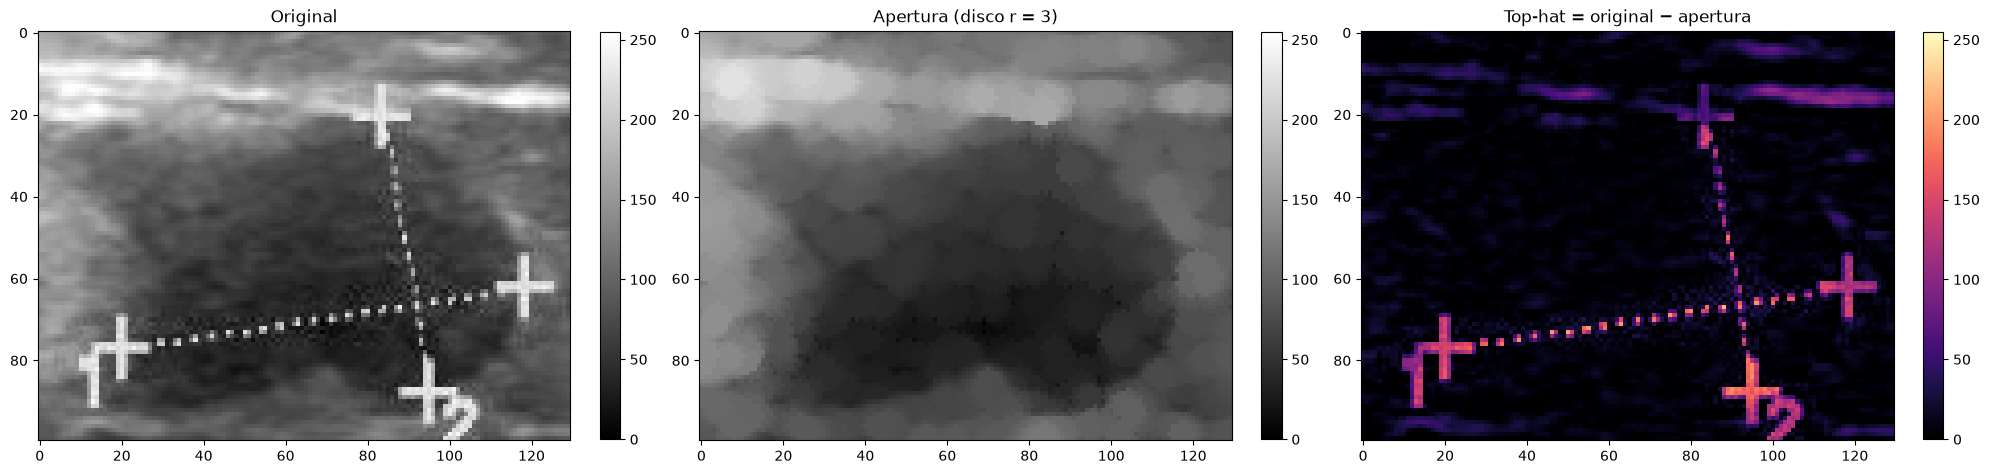

In [19]:
from skimage import morphology

disco = morphology.disk(3)                          # disco de radio 3 px (diámetro 7)
apertura = morphology.opening(recorte, disco)
top_hat = artefactos.tophat(recorte, radio=3)       # = recorte - apertura

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (titulo, im, cmap) in zip(axes, [("Original", recorte, "gray"),
                                         ("Apertura (disco r = 3)", apertura, "gray"),
                                         ("Top-hat = original − apertura", top_hat, "magma")]):
    h = ax.imshow(im, cmap=cmap, vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(titulo)
    plt.colorbar(h, ax=ax, fraction=0.035)
plt.tight_layout()
plt.show()

**Qué vemos:**
- En la **apertura** las cruces, la línea punteada y los números **desaparecieron**: el disco de 7 px de diámetro no entra en estructuras de 3 px, así que la erosión las borra y la dilatación no las puede recuperar. El tejido y el tumor quedan casi iguales.
- En el **top-hat** las marcas resaltan con valores altos (amarillo) y el tumor y el tejido quedan casi en 0. También aparecen, más tenues, algunas **fibras claras** del tejido (arriba del recorte), porque también son finas.

### 3.2 Elección del radio del disco

El radio decide qué tan "finas" tienen que ser las estructuras para aparecer en el *top-hat*:
- si el disco es **más chico** que alguna parte de las marcas, esa parte sobrevive a la apertura y **no se detecta**;
- si es **más grande** de lo necesario, también aparecen estructuras del tejido más gruesas (**fibras**).

Comparamos radios 2, 3 y 4 pintando de rojo los píxeles con *top-hat* ≥ 100 (el umbral se justifica en 3.3).

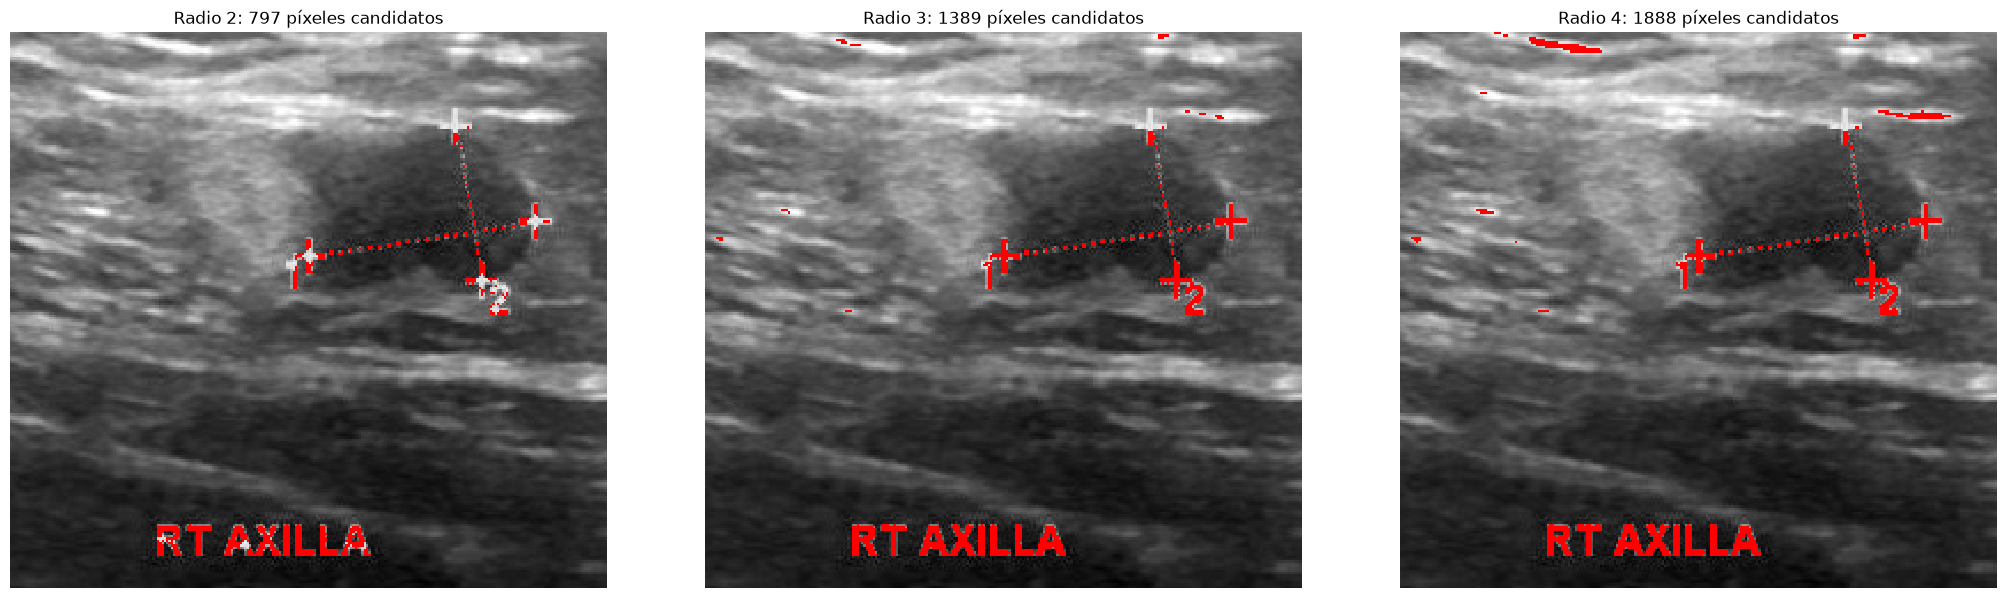

In [20]:
img_calipers, _ = cargar_caso(casos.loc["malignant (12)"])   # la imagen de los calipers (la variable img se reusó en la sección 2)

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, radio in zip(axes, [2, 3, 4]):
    candidatos = artefactos.tophat(img_calipers, radio) >= 100
    ax.imshow(pintar(img_calipers, candidatos)[150:392, 60:320], interpolation="nearest")
    ax.set_title(f"Radio {radio}: {candidatos.sum()} píxeles candidatos")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Qué vemos:**
- **Radio 2** (diámetro 5): las cruces quedan **incompletas** y el número "2" casi no se detecta. Las marcas miden 3 px de grosor en los brazos, pero en el centro de las cruces y en los números son más anchas, y ahí el disco de 5 px "entra" y la apertura no las borra.
- **Radio 3** (diámetro 7): detecta las **cruces completas**, la línea punteada, los números y el texto "RT AXILLA", con pocos píxeles de fibras.
- **Radio 4** (diámetro 9): detecta lo mismo que el radio 3, pero suma **más segmentos de fibras** (arriba del recorte).

Elegimos **radio 3**: es el más chico que detecta las marcas completas.

### 3.3 Elección del umbral

El *top-hat* da un valor por píxel; necesitamos un umbral que separe marcas de tejido. Medimos:
- el valor del *top-hat* **sobre las marcas**, en los mismos píxeles de los perfiles de la sección 1;
- el valor del *top-hat* **en el tejido**, como el percentil 99,9 en cinco imágenes **sin marcas** visibles (o sea, el valor que solo supera el 0,1 % más alto del tejido).

In [21]:
th_marcas = artefactos.tophat(img_calipers, 3)[170:270, 170:300]          # mismo recorte que en la sección 1
valores_marcas = np.concatenate([th_marcas[26, 83:86], th_marcas[61:64, 113]])
print("Top-hat sobre las marcas (perfil rojo y celeste):", valores_marcas.tolist())

sin_marcas = ["normal (21)", "benign (23)", "benign (404)", "normal (116)", "benign (344)"]
p999 = []
for id_caso in sin_marcas:
    im, _ = cargar_caso(casos.loc[id_caso])
    th = artefactos.tophat(im, 3)[10:, 10:]     # sin la esquina superior izquierda, donde está el logo del equipo
    p999.append(np.percentile(th, 99.9))
print("Top-hat en tejido, percentil 99,9:", np.round(p999).astype(int).tolist())

Top-hat sobre las marcas (perfil rojo y celeste): [123, 156, 125, 142, 151, 151]
Top-hat en tejido, percentil 99,9: [77, 51, 43, 53, 70]


**Qué vemos:** sobre las marcas el *top-hat* vale **entre 123 y 156**; en el tejido, el 99,9 % de los píxeles queda **por debajo de 43 a 77** según la imagen. Un umbral de **100** queda en el medio: deja pasar todas las marcas medidas con margen y solo lo supera una fracción muy chica del tejido (menos del 0,1 %).

### 3.4 Descartar fibras por su forma

Los pocos píxeles de tejido que superan el umbral son **fibras claras**. Para separarlas de las marcas usamos la **forma** de cada objeto:

1. **Etiquetado** (clase de Segmentación II): agrupamos los píxeles candidatos en componentes conexas, cada una es un "objeto".
2. Para cada objeto, `regionprops` le ajusta una elipse y da su **largo** (eje mayor), su **ancho** (eje menor) y su **orientación**.
3. `artefactos.es_fibra()` lo descarta si es **alargado** (largo ≥ 3 veces el ancho), **largo** (≥ 8 px) y **casi horizontal** (inclinación ≤ 35°).

**Por qué funciona:** en la mama el tejido se organiza en **capas paralelas a la piel**, así que las fibras se ven como trazos horizontales. Las marcas son cruces y puntos (compactos) o letras y números, que si son alargados son **verticales** (el "1", la "I").

Por último, `detectar_marcas()` **dilata** la máscara 2 px, para cubrir el borde suavizado de las marcas (la transición de ~145 que vimos en los perfiles de la sección 1) y los píxeles de los extremos que quedan justo por debajo del umbral. El valor de 2 px se eligió con la validación de la sección 5.5.

En el gráfico: **rojo** = marcas detectadas, **celeste** = candidatos descartados por ser fibras.

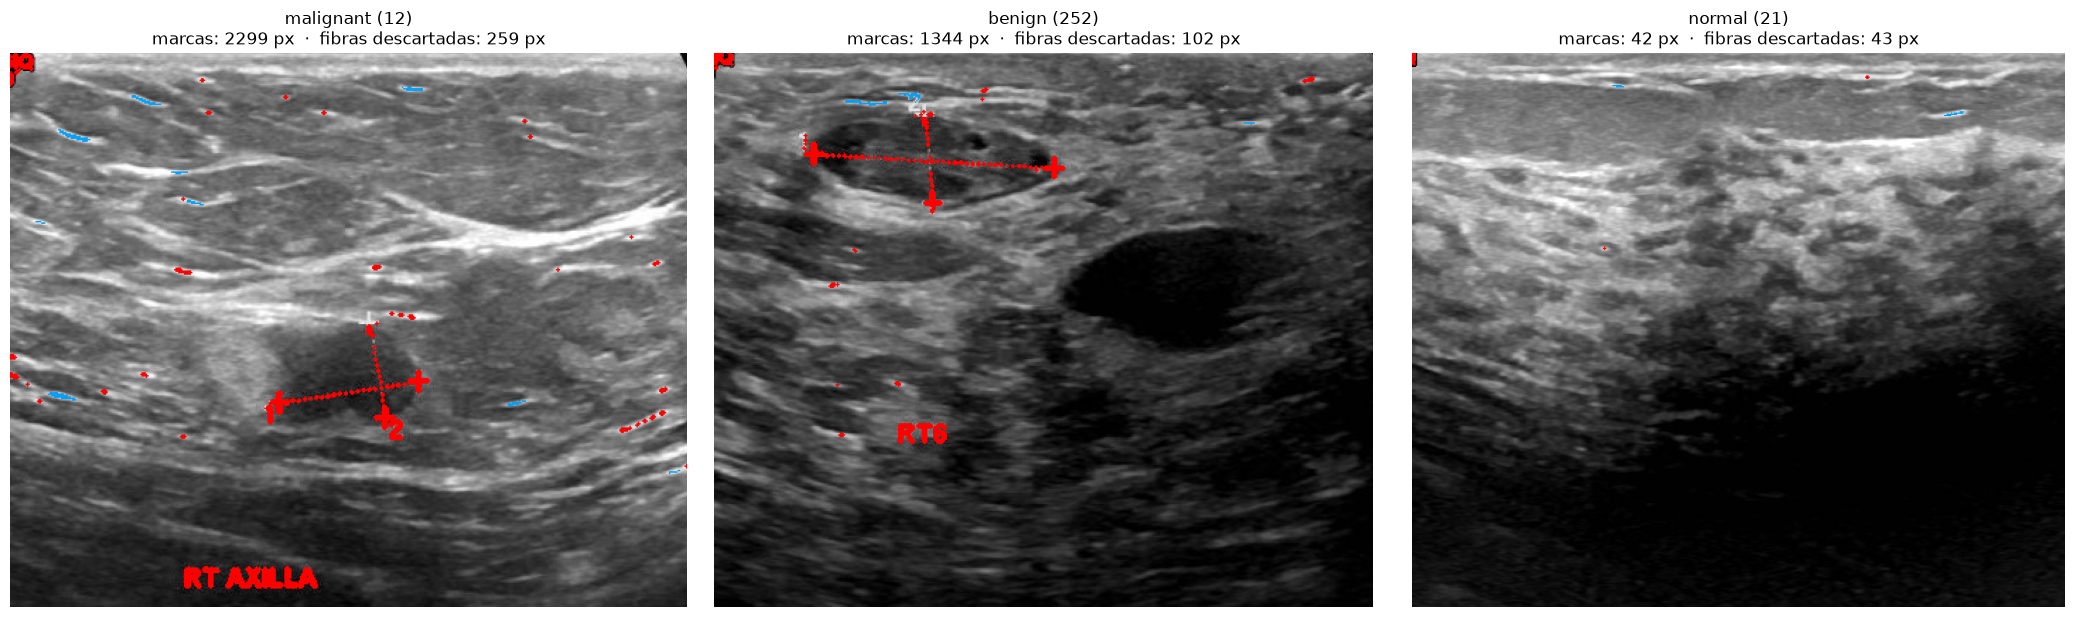

In [22]:
from skimage import measure

def mostrar_deteccion(ax, img, titulo):
    candidatos = artefactos.tophat(img, 3) >= 100
    etiquetas = measure.label(candidatos, connectivity=2)
    fibras = [r.label for r in measure.regionprops(etiquetas) if artefactos.es_fibra(r)]
    es_fibra = np.isin(etiquetas, fibras)
    marcas = artefactos.detectar_marcas(img)

    rgb = pintar(img, es_fibra, color=(0, 160, 255))
    rgb[marcas] = (255, 0, 0)
    ax.imshow(rgb)
    ax.set_title(f"{titulo}\nmarcas: {marcas.sum()} px  ·  fibras descartadas: {es_fibra.sum()} px")
    ax.axis("off")

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, id_caso in zip(axes, ["malignant (12)", "benign (252)", "normal (21)"]):
    im, _ = cargar_caso(casos.loc[id_caso])
    mostrar_deteccion(ax, im, id_caso)
plt.tight_layout()
plt.show()

**Qué vemos:**
- Los trazos **horizontales y largos** del tejido quedan en **celeste** (descartados).
- Las **cruces, líneas punteadas, números y textos** quedan en **rojo**, y también el **logo del equipo** en la esquina superior izquierda, que también es una marca.
- En `normal (21)`, que no tiene calipers, la mitad de los candidatos eran fibras y se descartaron (43 px); lo que queda en rojo es el logo y algunos puntos sueltos.
- Quedan algunos **puntos rojos chiquitos sobre fibras**: fragmentos cortos que no llegan a 8 px de largo. Son pocos píxeles y el *inpainting* los rellena con su entorno, así que su efecto es chico.

**Dos errores del detector que se ven acá:**
1. **Marcas sobre tejido brillante.** La cruz de arriba de `malignant (12)` está apoyada sobre una fibra clara: la apertura no la borra del todo porque el tejido alrededor también es claro, el *top-hat* queda por debajo de 100 y la cruz **no se detecta completa**. El *top-hat* mide contraste **local**, así que una marca clara sobre fondo claro es difícil de ver.
2. **Marcas pegadas a una fibra.** La cruz de arriba de `benign (252)` quedó en parte **celeste**: se tocó con una fibra horizontal, el etiquetado las juntó en **un solo objeto** alargado y horizontal, y el filtro de forma lo descartó entero como fibra.

Las dos son limitaciones a reportar. Se podrían reducir, por ejemplo, separando objetos pegados con una erosión antes del etiquetado, pero las dejamos así para no complicar el método: la validación de la sección 5 va a medir cuánto afectan.


### 3.5 Detección en todo el dataset

Aplicamos `detectar_marcas()` a las 780 imágenes y medimos qué porcentaje de cada imagen queda marcado. Tarda alrededor de medio minuto.

In [23]:
porcentaje = []
for id_caso, caso in casos.iterrows():
    im, _ = cargar_caso(caso)
    porcentaje.append(100 * artefactos.detectar_marcas(im).mean())
casos["pct_marcas"] = porcentaje

print(casos["pct_marcas"].describe(percentiles=[0.25, 0.5, 0.75]).round(2))
print(f"\nImágenes sin ninguna detección: {(casos['pct_marcas'] == 0).sum()}")
print("\nMediana por clase (%):")
print(casos.groupby("clase")["pct_marcas"].median().round(2))

count    780.00
mean       0.20
std        0.28
min        0.00
25%        0.04
50%        0.07
75%        0.23
max        1.53
Name: pct_marcas, dtype: float64

Imágenes sin ninguna detección: 34

Mediana por clase (%):
clase
benign       0.08
malignant    0.07
normal       0.05
Name: pct_marcas, dtype: float64


Miramos las tres imágenes con **más** detecciones (para ver si son marcas o errores) y tres **al azar**:

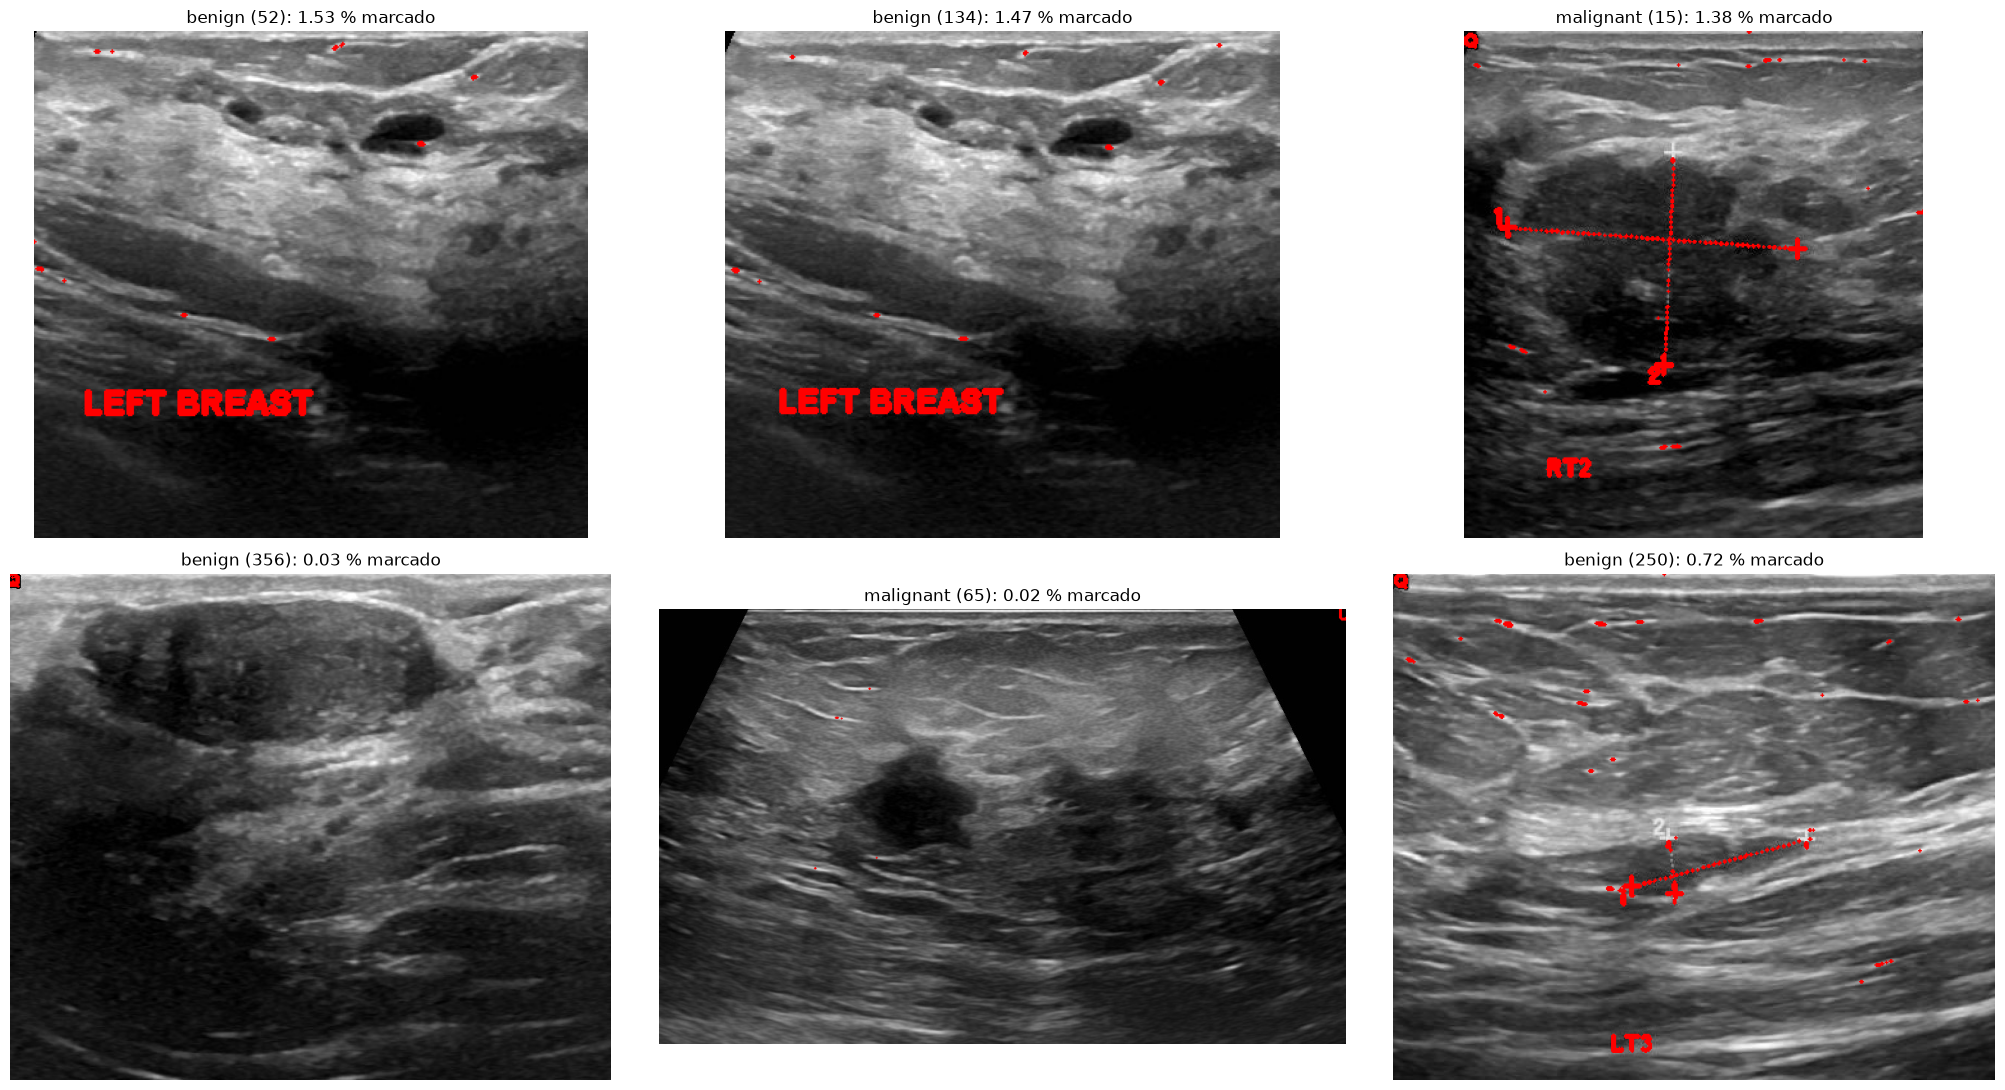

In [24]:
mas_detecciones = casos["pct_marcas"].nlargest(3).index.tolist()
al_azar = casos.sample(3, random_state=7).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(21, 11))
for ax, id_caso in zip(axes.flat, mas_detecciones + al_azar):
    im, _ = cargar_caso(casos.loc[id_caso])
    ax.imshow(pintar(im, artefactos.detectar_marcas(im)))
    ax.set_title(f"{id_caso}: {casos.loc[id_caso, 'pct_marcas']:.2f} % marcado")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Qué vemos:**
- Las marcas ocupan una parte **muy chica** de cada imagen: mediana **0,10 %** de los píxeles, y como máximo 2,3 %. Es parecido en las tres clases (0,08 a 0,12 %).
- Las imágenes con **más** detecciones tienen **marcas reales**: calipers completos con su línea punteada y textos grandes ("RT2", "LEFT BREAST"). No son errores del detector.
- En las imágenes al azar se detectan calipers y textos ("LT3"), y quedan algunos puntos sueltos sobre fibras (sección 3.4).
- 34 imágenes no tienen ninguna detección.

**Limitaciones:**
- No tenemos una "máscara verdadera" de las marcas para medir cuántas detectamos y cuántas se nos escapan. Por eso la **validación** se hace en la sección 5 con **marcas sintéticas**, donde sí sabemos dónde están.
- Las marcas **de color** (Doppler rojo y azul, en 16 imágenes) no son finas ni necesariamente claras en el canal que usamos, así que este detector no las cubre.

## 4. Reconstrucción con *inpainting*

### 4.1 Qué es el *inpainting*

Ya sabemos **dónde** están las marcas; ahora hay que reemplazar esos píxeles por algo parecido al tejido que había debajo. El tejido original se perdió (el ecógrafo lo sobrescribió al dibujar la marca), así que solo podemos **estimarlo a partir de los píxeles vecinos**. Eso es el ***inpainting***: rellenar un "hueco" de la imagen usando la información de su borde. Como las marcas tienen 3 px de grosor y la máscara se dilata 2 px, cada píxel del hueco tiene tejido real a pocos píxeles de distancia.

Probamos tres métodos, implementados en `artefactos.reconstruir()`:

| Método | Cómo rellena | Idea intuitiva |
|---|---|---|
| **Telea** (`cv2.INPAINT_TELEA`) | Avanza desde el borde del hueco hacia adentro, píxel por píxel. Cada píxel nuevo es un **promedio ponderado** de los píxeles ya conocidos a menos de 3 px, con más peso a los más cercanos. | "Ir cerrando el hueco desde afuera, copiando lo que hay alrededor." |
| **Navier-Stokes** (`cv2.INPAINT_NS`) | Prolonga hacia adentro del hueco las **líneas de igual nivel de gris** (isofotas) que llegan a su borde, con ecuaciones de la mecánica de fluidos. | "Si un borde entra al hueco, que lo atraviese y siga del otro lado." |
| **Biharmónico** (`skimage.restoration.inpaint_biharmonic`) | Busca la **superficie más suave** que coincide con los valores del borde del hueco. | "Tender una sábana que se apoye en el borde del hueco." |

Primero lo aplicamos con Telea a las dos imágenes con calipers, para ver el resultado completo: original, máscara detectada y reconstrucción.

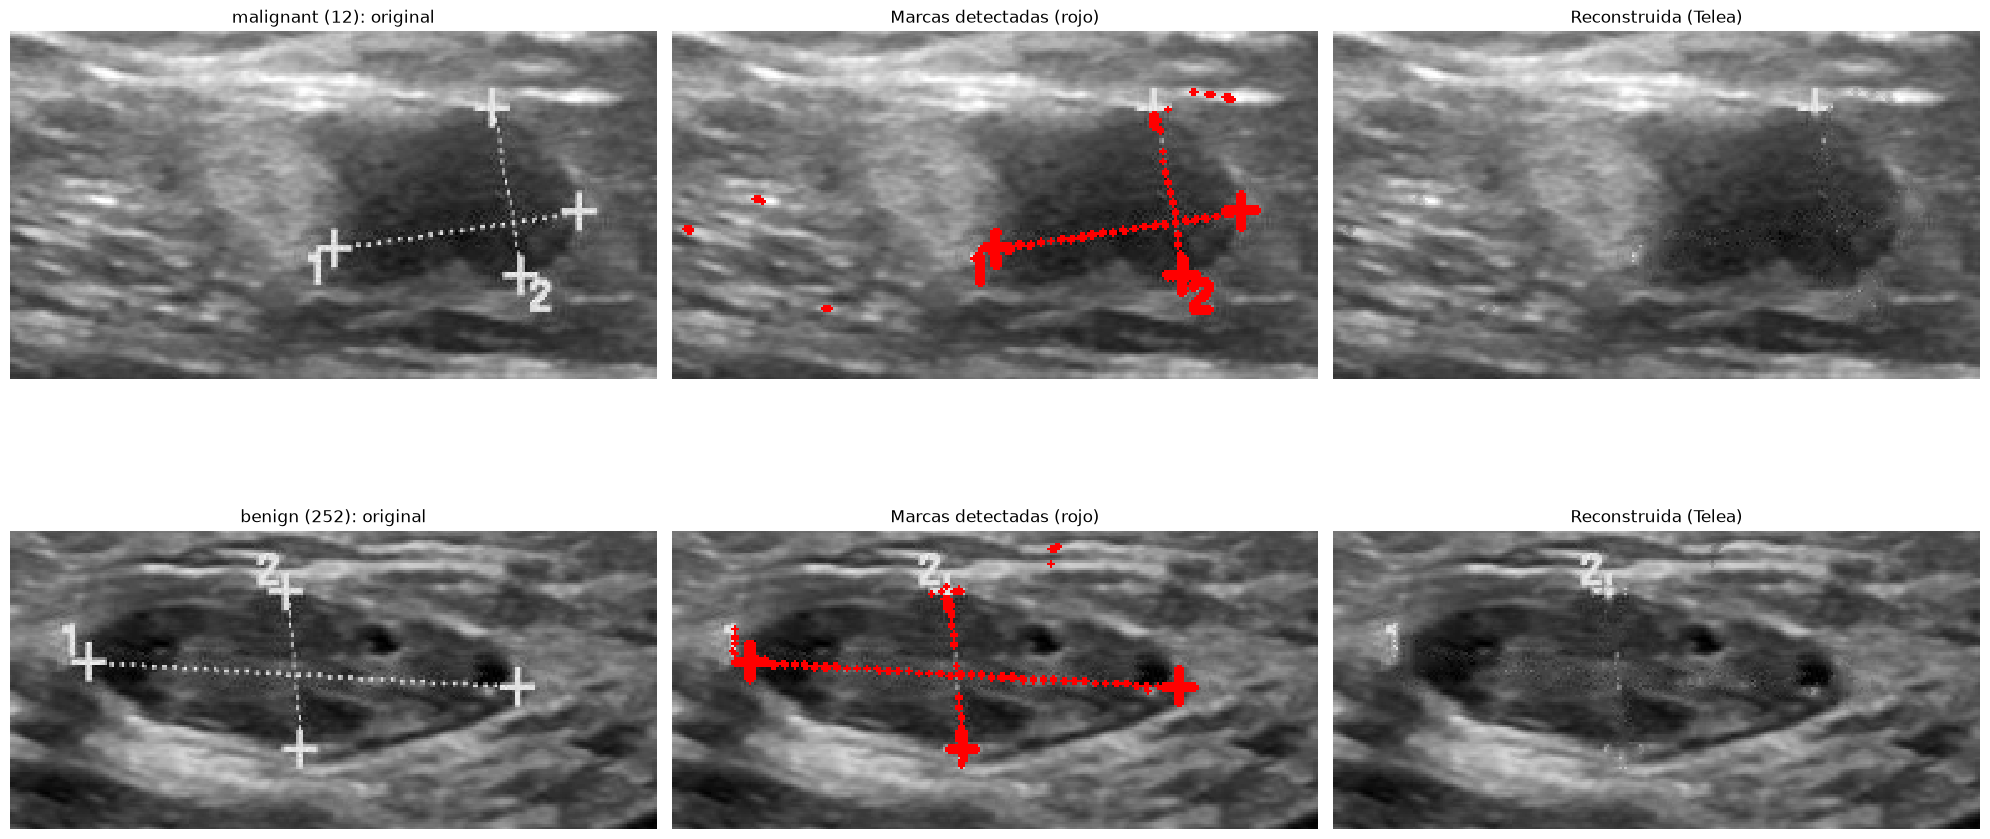

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for fila, (id_caso, zona) in zip(axes, [("malignant (12)", (slice(160, 300), slice(60, 320))),
                                       ("benign (252)", (slice(20, 140), slice(40, 300)))]):
    im, _ = cargar_caso(casos.loc[id_caso])
    marcas = artefactos.detectar_marcas(im)
    reconstruida = artefactos.reconstruir(im, marcas, radio=3, metodo="telea")

    fila[0].imshow(im[zona], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    fila[0].set_title(f"{id_caso}: original")
    fila[1].imshow(pintar(im, marcas)[zona], interpolation="nearest")
    fila[1].set_title("Marcas detectadas (rojo)")
    fila[2].imshow(reconstruida[zona], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    fila[2].set_title("Reconstruida (Telea)")
    for ax in fila:
        ax.axis("off")
plt.tight_layout()
plt.show()

**Qué vemos:**
- Donde la marca fue **detectada**, desaparece y queda tejido continuo: las cruces de abajo y de los costados, la línea punteada horizontal y los números de `malignant (12)`.
- Donde la marca **no** fue detectada, **sigue ahí**: la cruz de arriba de `malignant (12)` (apoyada sobre tejido brillante), y en `benign (252)` la cruz de arriba con su número "2" (la parte que se descartó como fibra) y restos del "1". Son los errores de detección de la sección 3.4: **el *inpainting* solo puede borrar lo que el detector encontró**.
- Quedan algunos **rastros tenues de la línea punteada vertical**, sobre todo cerca de las cruces no detectadas: algunos puntos tienen menos contraste y quedaron por debajo del umbral.


### 4.2 Comparación de los tres métodos

Mismo recorte de los calipers de `malignant (12)`, reconstruido con cada método.

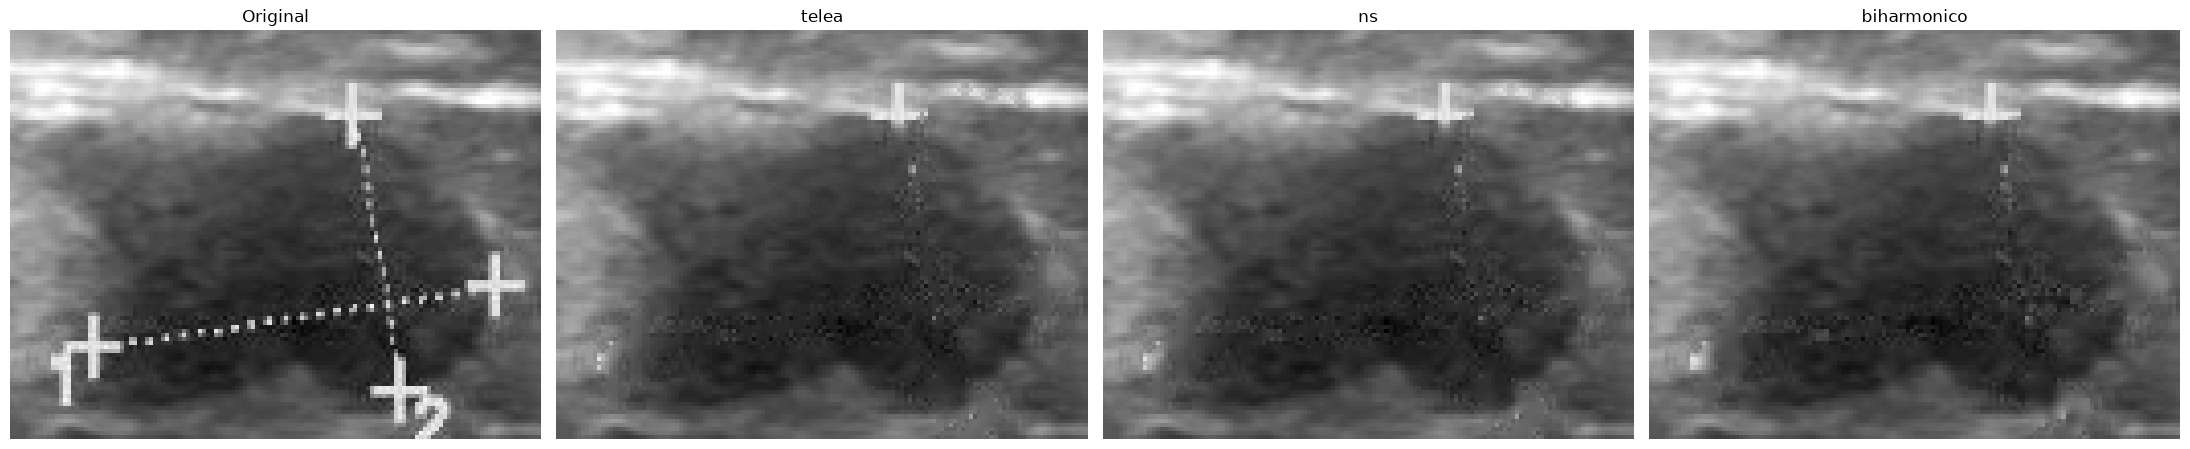

In [26]:
marcas_calipers = artefactos.detectar_marcas(img_calipers)
metodos = ["telea", "ns", "biharmonico"]
reconstrucciones = {m: artefactos.reconstruir(img_calipers, marcas_calipers, radio=3, metodo=m) for m in metodos}

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
axes[0].imshow(img_calipers[170:270, 170:300], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[0].set_title("Original")
for ax, m in zip(axes[1:], metodos):
    ax.imshow(reconstrucciones[m][170:270, 170:300], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(m)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Qué vemos:** a simple vista los tres resultados son **casi iguales**: el hueco es tan angosto (unos 7 px: la marca de 3 px más 2 px de dilatación de cada lado) que los tres métodos estiman valores parecidos a partir de los mismos vecinos. Mirar no alcanza para elegir: en la **sección 5** los comparamos con un **error medido** sobre marcas sintéticas.

### 4.3 ¿El relleno tiene la misma textura que el tejido?

El *inpainting* estima cada píxel a partir de sus vecinos, o sea que **interpola**. El speckle que había debajo de la marca era un patrón granular al azar que no se puede deducir del borde, así que esperamos que el relleno quede **más liso** que el tejido real.

Medirlo en las imágenes reales es difícil: **no sabemos qué tejido había debajo** de la marca, y compararlo con el tejido de al lado mezcla dos zonas distintas (una primera versión de este análisis daba resultados que cambiaban mucho con el tamaño de la ventana y del hueco). Por eso lo medimos en la **sección 5.4**, con marcas sintéticas, donde sí conocemos el tejido original y podemos comparar **los mismos píxeles** antes y después.

Importamos lo que vamos a usar en la validación:

In [ ]:
import cv2
import pandas as pd
from scipy import ndimage
from scipy.stats import wilcoxon

def desvio_local(im, ventana=3):
    """Desvío estándar en una ventana de ventana×ventana alrededor de cada píxel (medida simple de textura)."""
    im = im.astype(float)
    media = ndimage.uniform_filter(im, ventana)
    media_cuadrados = ndimage.uniform_filter(im ** 2, ventana)
    return np.sqrt(np.clip(media_cuadrados - media ** 2, 0, None))   # var = E[g²] − E[g]²

## 5. Validación con marcas sintéticas

Hasta ahora evaluamos el método **mirando**. Para medir qué tan bien funciona hace falta saber la **respuesta correcta**: dónde están las marcas y qué tejido había debajo. En las imágenes reales no lo sabemos.

La solución es **crear marcas nosotras**: dibujamos cruces falsas sobre tejido **limpio** de imágenes reales. Como guardamos la imagen original, sabemos **exactamente** dónde está cada cruz y qué había debajo. Eso permite medir:
1. **Detección:** qué porcentaje de cada cruz encuentra `detectar_marcas()`.
2. **Reconstrucción:** cuánto se parece el tejido rellenado al tejido original, con cada método.

### 5.1 Cómo son las marcas sintéticas

La validación solo vale si las cruces falsas **se parecen a las reales**. Por eso `artefactos.agregar_marcas_sinteticas()` las dibuja copiando lo que medimos en la sección 1:
- **3 px** de grosor, con valor **220** (las reales van de ~210 a 233);
- **1 px de transición** con la mitad de opacidad (~145), **de un solo lado** del trazo, como en los perfiles reales (`77, 145, 213, 233, 202, 81` y `66, 212, 221, 222, 144, 98`);
- brazos de **13 px**, como los calipers.

Se ubican al azar, pero **lejos de las marcas reales** (para no mezclarlas), **lejos del borde** de la imagen y **sobre tejido** (no sobre el fondo negro).

*Nota de proceso:* la primera versión de las cruces tenía la transición de los dos lados, y el detector fallaba mucho más que con las marcas reales. Al comparar los perfiles vimos que las cruces sintéticas eran más gruesas que las reales (5 px por encima de 145, contra 4). Ese detalle es suficiente para que el disco del *top-hat* "entre" en el centro de la cruz y no la detecte. Lo corregimos para que copien el perfil real.

In [ ]:
rng = np.random.default_rng(13)
im, _ = cargar_caso(casos.loc["benign (23)"])
zona_prohibida = cv2.dilate(artefactos.detectar_marcas(im).astype(np.uint8), np.ones((15, 15), np.uint8)).astype(bool)
marcada, mascara_sint, centros = artefactos.agregar_marcas_sinteticas(im, n=4, rng=rng, prohibida=zona_prohibida)
y, x = centros[0]

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
axes[0].imshow(marcada, cmap="gray", vmin=0, vmax=255)
for (cy, cx) in centros:
    axes[0].add_patch(plt.Rectangle((cx - 12, cy - 12), 24, 24, fill=False, edgecolor="lime"))
axes[0].set_title("benign (23) con 4 cruces sintéticas (recuadros verdes)")
axes[0].axis("off")

axes[1].imshow(marcada[y - 15:y + 16, x - 15:x + 16], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[1].set_title("Zoom sobre una cruz sintética")
axes[1].axis("off")

perfil_sint = marcada[y - 4, x - 5:x + 6]          # línea horizontal que cruza el brazo vertical
axes[2].plot(perfil_sint, "o-", color="green", label="cruz sintética")
axes[2].plot(perfil_rojo[5:16], "o--", color="red", alpha=0.6, label="marca real (perfil rojo)")
axes[2].plot(perfil_celeste[5:16], "o--", color="cyan", alpha=0.8, label="marca real (perfil celeste)")
axes[2].set_ylim(0, 255)
axes[2].set_xlabel("Posición (píxeles)")
axes[2].set_ylabel("Nivel de gris")
axes[2].set_title("Perfil: sintética vs. reales")
axes[2].legend()
plt.tight_layout()
plt.show()

**Qué vemos:** las cruces sintéticas tienen el mismo aspecto que los calipers reales, y su perfil tiene el mismo ancho (3 px por encima de 200 y 1 px de transición) y la misma altura. El nivel del tejido a los costados cambia según dónde cae cada cruz, pero la forma del pico es la misma.

### 5.2 Experimento

Tomamos **200 imágenes al azar** y en cada una dibujamos **3 cruces** (600 cruces en total). Para cada imagen:
1. corremos `detectar_marcas()` sobre la imagen con cruces y medimos, **para cada cruz**, qué fracción de sus píxeles detectó. Guardamos también el **brillo del tejido** alrededor de la cruz;
2. reconstruimos con los tres métodos usando la **máscara verdadera** de las cruces, y medimos el error contra la imagen original. Usar la máscara verdadera **aísla el error del *inpainting***: si usáramos la detectada, una cruz no detectada sumaría error aunque el método de relleno fuera perfecto;
3. reconstruimos también con la máscara **detectada** (el método completo, como se usaría en la práctica) y medimos el error en cada cruz.

**Cómo medimos el error de reconstrucción.** Dentro de los píxeles de las cruces calculamos:
- **MSE** (error cuadrático medio): el promedio de (original − reconstruida)². Cuanto **más bajo**, mejor.
- **PSNR** (relación señal a ruido pico) = $10 \cdot \log_{10}(255^2 / \text{MSE})$, en decibeles. Es el mismo error en escala logarítmica, relativo al máximo posible (255). Cuanto **más alto**, mejor. Como referencia: por debajo de ~20 dB las diferencias se notan mucho, y por encima de ~30 dB son chicas.

Tarda alrededor de medio minuto.

In [ ]:
rng = np.random.default_rng(13)
filas_marcas, filas_imagenes = [], []

for id_caso, caso in casos.sample(200, random_state=13).iterrows():
    im, _ = cargar_caso(caso)
    reales = artefactos.detectar_marcas(im)
    zona_prohibida = cv2.dilate(reales.astype(np.uint8), np.ones((15, 15), np.uint8)).astype(bool)
    marcada, verdad, centros = artefactos.agregar_marcas_sinteticas(im, n=3, rng=rng, prohibida=zona_prohibida)
    if not centros:
        continue

    detectada = artefactos.detectar_marcas(marcada)
    completa = artefactos.reconstruir(marcada, detectada)          # método completo: biharmónico sobre lo detectado

    # 1) detección y error del método completo, cruz por cruz
    for (y, x) in centros:
        zona = (slice(y - 8, y + 9), slice(x - 8, x + 9))
        cruz = np.zeros(im.shape, bool)
        cruz[zona] = verdad[zona]
        filas_marcas.append({
            "id": id_caso,
            "detectado": (detectada & cruz).sum() / cruz.sum(),     # fracción de la cruz detectada
            "brillo_tejido": im[zona][~verdad[zona]].mean(),        # tejido alrededor de la cruz (sin la cruz)
            "psnr_completo": artefactos.mse_psnr(im, completa, cruz)[1],
        })

    # 2) reconstrucción con la máscara verdadera, por método
    fila = {"id": id_caso, "sin reconstruir": artefactos.mse_psnr(im, marcada, verdad)[1]}
    interior = cv2.erode(verdad.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)   # sin el borde de la cruz
    desvio_original = np.median(desvio_local(im)[interior])
    for m in metodos:
        reconstruida = artefactos.reconstruir(marcada, verdad, metodo=m)
        fila[m] = artefactos.mse_psnr(im, reconstruida, verdad)[1]
        # textura: desvío local 3x3 del relleno / desvío local del tejido original, en los mismos píxeles
        fila[f"textura {m}"] = np.median(desvio_local(reconstruida)[interior]) / desvio_original

    # 3) qué fracción del tejido de esta imagen es "brillante" (media local > 120)
    media_local = ndimage.uniform_filter(im.astype(float), 15)
    tejido = media_local >= 20
    fila["frac_tejido_brillante"] = (media_local[tejido] > 120).mean()

    # 4) falsos positivos nuevos: detecciones que no son ni cruces sintéticas ni marcas reales
    # la detección dilata 2 px, así que excluimos 3 px alrededor de cada cruz
    cerca_de_cruces = cv2.dilate(verdad.astype(np.uint8), np.ones((7, 7), np.uint8)).astype(bool)
    fila["falsos_positivos_px"] = (detectada & ~reales & ~cerca_de_cruces).sum()
    filas_imagenes.append(fila)

val_marcas = pd.DataFrame(filas_marcas)
val_imagenes = pd.DataFrame(filas_imagenes)
print(f"{len(val_imagenes)} imágenes, {len(val_marcas)} cruces sintéticas")

### 5.3 Detección

Consideramos que una cruz quedó **detectada** si se encontró al menos el **80 %** de sus píxeles (lo que queda sin detectar es un borde chico que el *inpainting* casi no nota). Separamos las cruces según el **brillo del tejido** sobre el que cayeron.

In [ ]:
val_marcas["grupo_brillo"] = pd.cut(val_marcas["brillo_tejido"], [0, 60, 100, 120, 140, 255])
tabla_det = val_marcas.groupby("grupo_brillo", observed=True).agg(
    cruces=("detectado", "size"),
    fraccion_detectada_mediana=("detectado", "median"),
    porcentaje_cruces_detectadas=("detectado", lambda s: 100 * (s >= 0.8).mean()),
).round(2)
print(tabla_det)
print(f"\nEn total: {100 * (val_marcas['detectado'] >= 0.8).mean():.0f} % de las cruces detectadas")
print(f"Falsos positivos nuevos por imagen (mediana): {val_imagenes['falsos_positivos_px'].median():.0f} px")
print(f"Fracción del tejido con brillo local > 120 (mediana por imagen): {100 * val_imagenes['frac_tejido_brillante'].median():.0f} %")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(val_marcas["brillo_tejido"], 100 * val_marcas["detectado"], s=10, alpha=0.5)
ax.axvline(120, color="red", linestyle="--", label="220 − 100 = 120")
ax.set_xlabel("Brillo medio del tejido alrededor de la cruz")
ax.set_ylabel("% de la cruz detectado")
ax.set_title("Detección según el brillo del tejido")
ax.legend()
plt.show()

**Qué vemos:**
- Sobre tejido **oscuro o medio** (brillo hasta 100) el detector encuentra **el 96 al 100 % de las cruces**, completas.
- Entre 100 y 120 detecta la mitad; a partir de ~**120** la detección **se cae**, y por encima de 140 **no detecta ninguna**. El corte es muy marcado (línea roja).
- **No agrega falsos positivos**: la mediana de detecciones nuevas fuera de las cruces y de las marcas reales es 0 px.

**Por qué pasa:** el *top-hat* mide cuánto más clara es una estructura fina que su entorno, o sea, aproximadamente **valor de la marca − brillo del tejido**. Con marcas de 220 y umbral 100, la marca se detecta solo si $220 - \text{tejido} \geq 100$, es decir, **si el tejido es más oscuro que ~120**. Es exactamente el corte que se ve en el gráfico. Explica también el error que vimos en la sección 3.4: la cruz de arriba de `malignant (12)` estaba sobre una fibra clara.

**Cuánto importa:** alrededor de **un tercio del tejido** (33 %) tiene brillo local mayor a 120, así que una marca que cae ahí probablemente no se detecte. Dos cosas lo atenúan: los calipers se ubican sobre los bordes de la lesión, que es oscura, y los textos suelen ir en zonas de la imagen sin tejido brillante. Pero es la **principal limitación** del método. Bajar el umbral no lo resuelve: las fibras claras también superan umbrales más bajos (sección 3.3).

### 5.4 Reconstrucción: ¿qué método rellena mejor?

PSNR de cada método usando la máscara **verdadera** de las cruces, comparado con no reconstruir (dejar las cruces).

Para decidir si las diferencias entre métodos son reales usamos la **prueba de Wilcoxon de rangos con signo**: es la versión **pareada** de Mann-Whitney. Acá los tres métodos se aplicaron a **las mismas imágenes**, así que comparamos imagen por imagen ("en esta imagen, ¿cuál de los dos tuvo más PSNR?") en vez de comparar dos grupos independientes.

In [ ]:
columnas = ["sin reconstruir"] + metodos
print("PSNR mediano (dB):")
print(val_imagenes[columnas].median().round(1).to_string())

print("\nComparación pareada (Wilcoxon):")
for a, b in [("biharmonico", "ns"), ("biharmonico", "telea"), ("ns", "telea")]:
    p = wilcoxon(val_imagenes[a], val_imagenes[b]).pvalue
    gana = 100 * (val_imagenes[a] > val_imagenes[b]).mean()
    print(f"  {a:12s} vs {b:6s}: p = {p:.1e}   ({a} tiene más PSNR en el {gana:.0f} % de las imágenes)")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot([val_imagenes[c] for c in columnas], tick_labels=columnas)
ax.set_ylabel("PSNR dentro de las cruces (dB)")
ax.set_title("Error de reconstrucción por método (más alto = mejor)")
plt.show()

print("\nTextura del relleno (desvío local 3×3 del relleno / desvío local del tejido original, mismos píxeles):")
for m in metodos:
    r = val_imagenes[f"textura {m}"].median()
    print(f"  {m:12s} {r:.2f}  ->  el relleno conserva el {100 * r:.0f} % de la variación local del tejido original")

**Qué vemos:**
- **Sin reconstruir**, el PSNR dentro de las cruces es de ~6 dB: las marcas son muy distintas del tejido.
- Los tres métodos lo llevan a **~30 dB o más**: el tejido rellenado queda muy cerca del original.
- El **biharmónico es el más exacto** (mediana 33,3 dB, contra 30,2 de Navier-Stokes y 29,5 de Telea). Supera a los otros dos en el 96–98 % de las imágenes, y la diferencia es significativa (p < 10⁻³⁰).
- En **textura**, ninguno recupera el speckle: el relleno conserva entre el **73 y el 86 %** de la variación local del tejido original, o sea que queda más liso, como esperábamos (sección 4.3). El biharmónico es el más liso (73 %), Navier-Stokes el que más variación conserva (86 %).

**Un compromiso entre exactitud y textura.** El biharmónico tiene el menor error justamente **porque** rellena suave: cuando no se puede saber cómo era el speckle (es aleatorio), lo que minimiza el error cuadrático es "apostar al promedio" del entorno. Navier-Stokes agrega más variación, pero esa variación no es el speckle real (por eso su error es mayor).

**Elegimos el biharmónico**, porque el objetivo de esta parte es que los valores reconstruidos sean lo más parecidos posible a los reales, y la diferencia de textura con Telea es chica (73 vs 77 %). Queda como método por defecto en `artefactos.reconstruir()` y en `artefactos.limpiar()`, la función que van a usar las partes siguientes. Como las marcas ocupan alrededor del 0,1 % de cada imagen, el relleno algo más liso tiene un efecto muy chico en el análisis de textura de las partes siguientes.

### 5.5 ¿Cuánto dilatar la máscara?

En la primera versión del detector la máscara se dilataba **1 px**, pensando en cubrir el píxel de transición. Al medir el error del método completo vimos un problema: aunque una cruz se detectara casi entera, el PSNR quedaba bajo (~22 dB). El **MSE castiga mucho los pocos píxeles de la marca que quedan sin borrar**: un píxel que sigue valiendo 220 sobre tejido de 70 aporta un error de 150² = 22.500. Con que se escapen 2 o 3 píxeles de una cruz, el error se dispara.

Comparamos dilatar 1, 2 y 3 px. Medimos solo sobre las cruces en tejido con brillo ≤ 100, donde el detector funciona (sección 5.3), para separar este efecto del de las marcas no detectadas. Tarda alrededor de un minuto.

In [ ]:
filas = []
for dilatar in [1, 2, 3]:
    rng = np.random.default_rng(13)            # misma semilla: mismas cruces en las mismas posiciones
    for id_caso, caso in casos.sample(200, random_state=13).iterrows():
        im, _ = cargar_caso(caso)
        reales = artefactos.detectar_marcas(im)
        zona_prohibida = cv2.dilate(reales.astype(np.uint8), np.ones((15, 15), np.uint8)).astype(bool)
        marcada, verdad, centros = artefactos.agregar_marcas_sinteticas(im, n=3, rng=rng, prohibida=zona_prohibida)
        if not centros:
            continue
        detectada = artefactos.detectar_marcas(marcada, dilatar=dilatar)
        reconstruida = artefactos.reconstruir(marcada, detectada)
        for (y, x) in centros:
            zona = (slice(y - 8, y + 9), slice(x - 8, x + 9))
            cruz = np.zeros(im.shape, bool)
            cruz[zona] = verdad[zona]
            filas.append({"dilatar (px)": dilatar,
                          "brillo_tejido": im[zona][~verdad[zona]].mean(),
                          "cubierta_100": (detectada & cruz).sum() == cruz.sum(),
                          "psnr": artefactos.mse_psnr(im, reconstruida, cruz)[1]})

ajuste = pd.DataFrame(filas)
ajuste = ajuste[ajuste["brillo_tejido"] <= 100]
print(ajuste.groupby("dilatar (px)").agg(
    cruces=("psnr", "size"),
    pct_cruces_cubiertas_completas=("cubierta_100", lambda s: 100 * s.mean()),
    psnr_mediano=("psnr", "median"),
).round(1))

**Qué vemos:**
- Con **1 px**, solo el 10 % de las cruces queda **cubierta por completo**: casi siempre quedan algunos píxeles de los extremos o del borde sin borrar, y el PSNR mediano es de 21,6 dB.
- Con **2 px**, el 94 % de las cruces queda cubierta por completo y el PSNR sube a 31,3 dB.
- Con **3 px** se cubre casi lo mismo (95 %), pero el PSNR **baja** a 29,7 dB: el hueco a rellenar es más grande, así que el *inpainting* tiene que inventar más tejido y se equivoca más.

**Elegimos dilatar 2 px**, que es el valor por defecto de `detectar_marcas()`. Las secciones 3 y 4 de este notebook ya usan ese valor.

### 5.6 El método completo

Error del método completo (detección con dilatación de 2 px + biharmónico) sobre las 600 cruces de la sección 5.2, según **qué porcentaje de cada cruz se detectó**.

In [ ]:
val_marcas["porcentaje_detectado"] = pd.cut(100 * val_marcas["detectado"], [-1, 50, 80, 99.9, 100],
                                             labels=["menos de 50 %", "50 a 80 %", "80 a 99,9 %", "100 %"])
print(val_marcas.groupby("porcentaje_detectado", observed=True)["psnr_completo"].agg(cruces="size", psnr_mediano="median").round(1))

**Qué vemos:**
- Cuando la cruz se detecta **completa** (352 de las 600), queda reconstruida con un PSNR mediano de **31,6 dB**: casi igual que con la máscara verdadera (33,3 dB).
- Si queda **algo sin detectar**, aunque sea poco (80 a 99,9 %), el PSNR cae a ~15 dB: los píxeles de marca que quedan pesan mucho en el error.
- Las cruces **no detectadas** (menos del 50 %, casi todas sobre tejido brillante) quedan casi como estaban, con ~12 dB.

El rendimiento del método completo depende entonces casi todo de la **detección**: cuando la marca se detecta entera, la reconstrucción es buena.

## 6. Lo que la validación nos hizo corregir

Medir con marcas sintéticas no solo sirvió para dar números finales: también mostró **errores en versiones anteriores del método y del análisis**, que corregimos. Los dejamos registrados porque muestran por qué hace falta validar en vez de confiar en lo que se ve.

1. **Las primeras cruces sintéticas no se parecían a las reales.** La primera versión tenía brazos de 5 px; la segunda, el borde suavizado de los dos lados del trazo. En ambos casos el detector fallaba mucho más que con las marcas reales, porque el disco del *top-hat* "entraba" en el centro de las cruces gruesas y la apertura no las borraba. Al compararlas con los perfiles reales (sección 1) vimos que **el borde suavizado está de un solo lado** y lo corregimos (sección 5.1). Una validación con datos sintéticos solo es válida si los datos sintéticos se parecen a los reales.

2. **La dilatación de 1 px era insuficiente.** La habíamos elegido para cubrir el píxel de transición de las marcas, pero la validación mostró que casi siempre quedaban 2 o 3 píxeles de la marca sin borrar (solo el 10 % de las cruces quedaba cubierta por completo), y esos pocos píxeles bastan para que el error se dispare. Con 2 px se cubre el 94 % y el PSNR sube de 21,6 a 31,3 dB (sección 5.5). Por este cambio se actualizaron los resultados de las secciones 3 y 4.

3. **La medida de textura del relleno sobre imágenes reales no era confiable.** Comparábamos el desvío local del relleno con el del tejido vecino, usando una ventana de 7 × 7. Esa ventana mezclaba píxeles del relleno con píxeles de tejido, y el resultado cambiaba mucho con el tamaño del hueco: con la dilatación de 1 px daba que el relleno tenía 10–17 % menos textura, y con la de 2 px daba que tenía la misma. La reemplazamos por una comparación con el **tejido original en los mismos píxeles**, que solo es posible con marcas sintéticas (sección 5.4). Así apareció el **compromiso entre exactitud y textura** del biharmónico.

4. **Una afirmación sobre duplicados era incorrecta.** En una versión anterior dijimos que `benign (52)` y `benign (134)` eran la misma imagen. Al compararlas tienen tamaños apenas distintos (338 × 370 y 345 × 378 px): son **casi duplicadas**, la misma escena recortada distinto, no idénticas. Igual confirma que BUSI tiene imágenes repetidas, como vimos en la Parte 0.

## 7. Conclusiones de la Parte 1

| Pregunta | Respuesta | Evidencia |
|---|---|---|
| ¿Cómo son las marcas? | Finas (3 px), de 210 a 233, con 1 px de transición de un lado | Perfiles de intensidad (sección 1) |
| ¿Sirve buscar el blanco puro? | No: el ≥ 250 es casi siempre tejido brillante, y las marcas no son 255 | Sección 2 |
| ¿Cómo detectarlas? | *Top-hat* con disco de radio 3, umbral 100, descarte de fibras horizontales por forma y dilatación de 2 px | Radio y umbral elegidos con datos (sección 3); dilatación con la validación (sección 5.5) |
| ¿Cuánto ocupan? | Mediana de 0,10 % de cada imagen | 780 imágenes (sección 3.5) |
| ¿Qué tan bien se detectan? | 96–100 % de las cruces sobre tejido con brillo ≤ 100; casi ninguna sobre tejido > 120; sin falsos positivos nuevos | 600 cruces sintéticas (sección 5.3) |
| ¿Con qué rellenar? | **Biharmónico**: PSNR 33,3 dB vs 30,2 (NS) y 29,5 (Telea) | Wilcoxon pareado, p < 10⁻³⁰ (sección 5.4) |
| ¿Qué se pierde? | El relleno conserva el 73 % de la variación local del tejido: queda más liso | Comparación con el tejido original (sección 5.4) |
| ¿Cómo funciona todo junto? | 31,6 dB cuando la marca se detecta completa | Sección 5.6 |

**Limitaciones:**
1. **Marcas sobre tejido brillante:** el *top-hat* mide contraste local, así que una marca sobre tejido con brillo mayor a ~120 (un tercio del tejido) no se detecta. Es la limitación principal.
2. **Marcas pegadas a fibras:** pueden descartarse junto con la fibra en el filtro de forma (sección 3.4).
3. **Marcas de color** (Doppler, 16 imágenes): no se tratan.
4. **El relleno es más liso** que el tejido real, porque el *inpainting* interpola y no puede recuperar el speckle. Hay un compromiso entre exactitud (biharmónico) y variación (Navier-Stokes).
5. **Las cruces sintéticas** imitan a los calipers, pero no a los textos ni a las líneas punteadas.

**Para las partes siguientes:** usar `artefactos.limpiar(img)`, que devuelve la imagen sin marcas y la máscara de lo que se borró. La **Parte 2** (ruido) puede repetir su análisis sobre las imágenes limpias en vez de excluir los píxeles ≥ 250 (que, como vimos en la sección 2, son tejido y no marcas).